# Motor Insurance Fraud Detection
## Final Exercise

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktnspr/py4lju/blob/main/07_fraud_detection_solution.ipynb)

Build a classifier that detects fraudulent motor insurance claims. Work through three phases:

- **Phase 1**: Exploration
- **Phase 2**: Preparation and Modelling
- **Phase 3**: Evaluation

### The Dataset: `vehicle_fraud.csv`

10,050 rows of synthetic motor insurance claims:

| Column | Description |
|--------|-------------|
| `claim_id` | Claim number |
| `policyholder_age` | Age in years |
| `occupation` | `Employed`, `Self-employed`, `Unemployed`, `Student` |
| `region` | Postcode region `PLZ_01` to `PLZ_10` |
| `schufa_score` | Credit score (300–850) |
| `customer_since_years` | Years as a customer |
| `vehicle_value` | Vehicle value |
| `vehicle_type` | `Compact`, `Mid-range`, `Luxury`, `SUV`, `Sports car` |
| `coverage_type` | `Liability`, `Partial coverage`, `Comprehensive` |
| `number_of_prior_claims` | Number of earlier claims |
| `claim_amount` | Claim amount |
| `police_report` | `1` if a police report was filed |
| `witnesses_present` | `1` if witnesses were present |
| `reporting_delay_days` | Days between accident and claim report |
| `fraud` | Target: `1` = fraudulent, `0` = legitimate |

In [1]:
# Colab setup: fetch the dataset if not running locally
import sys
if 'google.colab' in sys.modules:
    !wget -qN https://raw.githubusercontent.com/ktnspr/py4lju/main/vehicle_fraud.csv

In [2]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, precision_recall_curve)
from sklearn.inspection import permutation_importance

# Seaborn style for all plots
sns.set_theme(style='whitegrid')

# Avoid truncation of DataFrame output in Jupyter
pd.set_option('display.expand_frame_repr', False)

# Display all columns in the DataFrame output
pd.set_option('display.max_columns', None)

# Define a separator for better readability
sep = "=" * 50

In [3]:
# Load the dataset
df = pd.read_csv('vehicle_fraud.csv')
df.head()

,claim_id,policyholder_age,occupation,region,schufa_score,customer_since_years,vehicle_value,vehicle_type,coverage_type,number_of_prior_claims,claim_amount,police_report,witnesses_present,reporting_delay_days,fraud
0,108777,38,Unemployed,PLZ_05,575.0,14,75699.57,Luxury,Liability,2,15055.72,0,0,31,0
1,102200,42,Employed,PLZ_10,653.0,21,70254.54,Sports car,Partial coverage,2,4751.62,1,0,16,0
2,109597,27,Self-employed,PLZ_09,525.0,2,9686.20,Compact,Comprehensive,2,7600.43,0,0,44,0
3,108491,43,Employed,PLZ_03,619.0,14,77918.56,Compact,Comprehensive,2,7524.33,0,1,31,0
4,103315,45,Student,PLZ_04,624.0,8,3660.94,Luxury,Partial coverage,4,25664.09,0,0,33,1


## Phase 1: Exploration

### 1.1 Overview

1. How many rows and columns does the dataset have? Which columns are numeric, which are text?
2. Are there missing values?
3. What is the fraud rate?

In [4]:
# Task 1: Shape
print(f"\n{sep}\nShape: df.shape\n{sep}")
print(df.shape)


Shape: df.shape
(10050, 15)


In [5]:
# Task 1: Data types
print(f"\n{sep}\nData Types: df.info()\n{sep}")
df.info()


Data Types: df.info()
<class 'pandas.DataFrame'>
RangeIndex: 10050 entries, 0 to 10049
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   claim_id                10050 non-null  int64  
 1   policyholder_age        10050 non-null  int64  
 2   occupation              10050 non-null  str    
 3   region                  10050 non-null  str    
 4   schufa_score            9522 non-null   float64
 5   customer_since_years    10050 non-null  int64  
 6   vehicle_value           10050 non-null  float64
 7   vehicle_type            10050 non-null  str    
 8   coverage_type           10050 non-null  str    
 9   number_of_prior_claims  10050 non-null  int64  
 10  claim_amount            10050 non-null  float64
 11  police_report           10050 non-null  int64  
 12  witnesses_present       10050 non-null  int64  
 13  reporting_delay_days    10050 non-null  int64  
 14  fraud                   10

In [6]:
# Task 2: Missing values
print(f"\n{sep}\nMissing Values: df.isna().sum()\n{sep}")
print(df.isna().sum())


Missing Values: df.isna().sum()
claim_id                    0
policyholder_age            0
occupation                  0
region                      0
schufa_score              528
customer_since_years        0
vehicle_value               0
vehicle_type                0
coverage_type               0
number_of_prior_claims      0
claim_amount                0
police_report               0
witnesses_present           0
reporting_delay_days        0
fraud                       0
dtype: int64


In [7]:
# Task 3: Fraud rate
print(f"\n{sep}\nFraud Rate: df['fraud'].value_counts(normalize=True)\n{sep}")
print(df['fraud'].value_counts(normalize=True))


Fraud Rate: df['fraud'].value_counts(normalize=True)
fraud
0    0.881592
1    0.118408
Name: proportion, dtype: float64


`schufa_score` is missing in 528 rows. Only about 12% of the claims are fraudulent: the classes are **imbalanced**. A model that always predicts "no fraud" reaches 88% accuracy but catches no fraud at all.

### 1.2 Distributions

1. Plot a histogram of `claim_amount`. Is it symmetric or skewed?
2. Compare `claim_amount` for fraudulent and legitimate claims with a box plot.

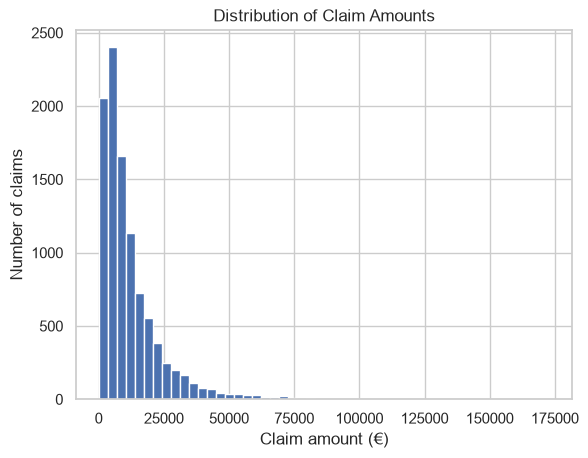

In [8]:
# Task 1: Histogram of claim_amount
df['claim_amount'].plot(kind='hist', bins=50)
plt.title('Distribution of Claim Amounts')
plt.xlabel('Claim amount (€)')
plt.ylabel('Number of claims')
plt.show()

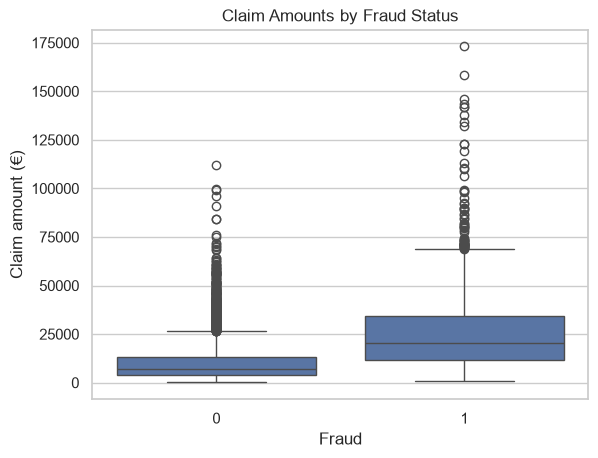

In [9]:
# Task 2: Box plot of claim_amount by fraud
sns.boxplot(data=df, x='fraud', y='claim_amount')
plt.title('Claim Amounts by Fraud Status')
plt.xlabel('Fraud')
plt.ylabel('Claim amount (€)')
plt.show()

`claim_amount` is strongly right-skewed: most claims are small, a few are very large. Fraudulent claims are higher on average.

### 1.3 Fraud Patterns

1. Compare the mean of every numeric column for `fraud == 0` and `fraud == 1`.
2. Compute the correlation of every numeric column with `fraud` and sort it.
3. Compute the fraud rate for each combination of `police_report` and `witnesses_present`.
4. Compute the fraud rate for new customers (`customer_since_years < 3`) with many prior claims (`number_of_prior_claims >= 3`).

In [10]:
# Task 1: Means by fraud status
print(f"\n{sep}\nMeans by Fraud Status: df.groupby('fraud').mean(numeric_only=True)\n{sep}")
print(df.groupby('fraud').mean(numeric_only=True).round(2))


Means by Fraud Status: df.groupby('fraud').mean(numeric_only=True)
        claim_id  policyholder_age  schufa_score  customer_since_years  vehicle_value  number_of_prior_claims  claim_amount  police_report  witnesses_present  reporting_delay_days
fraud                                                                                                                                                                              
0      105007.78             50.12         607.6                 14.95       44119.38                    1.50       9979.53           0.53               0.52                 23.37
1      104997.65             45.44         551.3                 11.34       15695.27                    2.35      26787.00           0.32               0.34                 32.32


In [11]:
# Task 2: Correlation with fraud
print(f"\n{sep}\nCorrelation with Fraud: df.corr(numeric_only=True)['fraud'].sort_values()\n{sep}")
print(df.corr(numeric_only=True)['fraud'].sort_values().round(3))


Correlation with Fraud: df.corr(numeric_only=True)['fraud'].sort_values()
vehicle_value            -0.400
schufa_score             -0.239
customer_since_years     -0.232
policyholder_age         -0.153
police_report            -0.134
witnesses_present        -0.117
claim_id                 -0.001
number_of_prior_claims    0.205
reporting_delay_days      0.262
claim_amount              0.421
fraud                     1.000
Name: fraud, dtype: float64


In [12]:
# Task 3: Fraud rate by documentation
print(f"\n{sep}\nFraud Rate by Documentation: df.groupby(['police_report', 'witnesses_present'])['fraud'].mean()\n{sep}")
print(df.groupby(['police_report', 'witnesses_present'])['fraud'].mean().unstack().round(3))


Fraud Rate by Documentation: df.groupby(['police_report', 'witnesses_present'])['fraud'].mean()
witnesses_present      0      1
police_report                  
0                  0.204  0.110
1                  0.098  0.057


In [13]:
# Task 4: Fraud rate of new customers with many prior claims
new_many = (df['customer_since_years'] < 3) & (df['number_of_prior_claims'] >= 3)

print(f"\n{sep}\nFraud Rate of New Customers with Many Prior Claims: df.groupby(new_many)['fraud'].mean()\n{sep}")
print(df.groupby(new_many)['fraud'].mean().round(3))


Fraud Rate of New Customers with Many Prior Claims: df.groupby(new_many)['fraud'].mean()
False    0.114
True     0.630
Name: fraud, dtype: float64


Fraudulent claims have higher claim amounts on cheaper vehicles. Fraudsters also have a lower `schufa_score`, report later and are newer customers. Without police report and witnesses, the fraud rate doubles to about 20%. New customers with many prior claims have a fraud rate of over 60%.

## Phase 2: Preparation and Modelling

### 2.1 Cleaning

1. How many rows are duplicates? Remove them.
2. Find the impossible ages with `describe()` and replace them with `np.nan`.
3. Add the indicator column `schufa_missing`. Compare the fraud rate of claims with and without `schufa_score`.

In [14]:
# Task 1: Duplicates
print(f"\n{sep}\nDuplicates: df.duplicated().sum()\n{sep}")
print(df.duplicated().sum())


Duplicates: df.duplicated().sum()
50


In [15]:
# Remove the duplicates
df = df.drop_duplicates()

print(f"\n{sep}\nNumber of Rows: len(df)\n{sep}")
print(len(df))


Number of Rows: len(df)
10000


In [16]:
# Task 2: Impossible ages
print(f"\n{sep}\nAge Statistics: df['policyholder_age'].describe()\n{sep}")
print(df['policyholder_age'].describe())


Age Statistics: df['policyholder_age'].describe()
count    10000.000000
mean        49.560800
std          9.886217
min          0.000000
25%         43.000000
50%         50.000000
75%         56.000000
max         80.000000
Name: policyholder_age, dtype: float64


In [17]:
# Replace the impossible ages with NaN
df.loc[df['policyholder_age'] < 18, 'policyholder_age'] = np.nan

print(f"\n{sep}\nMissing Ages: df['policyholder_age'].isna().sum()\n{sep}")
print(df['policyholder_age'].isna().sum())


Missing Ages: df['policyholder_age'].isna().sum()
30


In [18]:
# Task 3: Indicator column and fraud rate
df['schufa_missing'] = df['schufa_score'].isna().astype(int)

print(f"\n{sep}\nFraud Rate by schufa_missing: df.groupby('schufa_missing')['fraud'].mean()\n{sep}")
print(df.groupby('schufa_missing')['fraud'].mean().round(3))


Fraud Rate by schufa_missing: df.groupby('schufa_missing')['fraud'].mean()
schufa_missing
0    0.106
1    0.335
Name: fraud, dtype: float64


The minimum age of 0 is a placeholder for an unknown age. Without a credit score, the fraud rate triples from 11% to 34%.

### 2.2 Feature Engineering

Create four new columns:

1. `claim_value_ratio` = `claim_amount` / `vehicle_value`
2. `no_report_no_witness` = `1` if there is neither a police report nor witnesses
3. `new_customer_many_claims` = `1` for customers with `customer_since_years < 3` and `number_of_prior_claims >= 3`
4. `log_claim_amount` = `np.log(claim_amount)` for the skewed claim amounts

Then compare the mean `claim_value_ratio` for fraudulent and legitimate claims.

In [19]:
# Task 1: Claim-to-value ratio
df['claim_value_ratio'] = df['claim_amount'] / df['vehicle_value']

In [20]:
# Task 2: Neither police report nor witnesses
df['no_report_no_witness'] = ((df['police_report'] == 0) & (df['witnesses_present'] == 0)).astype(int)

In [21]:
# Task 3: New customer with many prior claims
df['new_customer_many_claims'] = ((df['customer_since_years'] < 3) & (df['number_of_prior_claims'] >= 3)).astype(int)

In [22]:
# Task 4: Log-transformed claim amount
df['log_claim_amount'] = np.log(df['claim_amount'])

In [23]:
# Mean claim_value_ratio by fraud status
print(f"\n{sep}\nMean Claim-to-Value Ratio by Fraud Status: df.groupby('fraud')['claim_value_ratio'].mean()\n{sep}")
print(df.groupby('fraud')['claim_value_ratio'].mean().round(3))


Mean Claim-to-Value Ratio by Fraud Status: df.groupby('fraud')['claim_value_ratio'].mean()
fraud
0    0.301
1    3.521
Name: claim_value_ratio, dtype: float64


### 2.3 Encoding, Split, Missing Values and Scaling

1. One-hot encode `occupation`, `region`, `vehicle_type` and `coverage_type` with `pd.get_dummies()`. Store the result in `df_encoded`.
2. Split into features `X` (without `claim_id` and `fraud`) and target `y`.
3. Split into 80% training and 20% test data. `stratify=y` keeps the fraud rate equal in both sets.
4. Fill the missing values in both sets with the medians of the training data.
5. Scale the features with `StandardScaler`. Fit the scaler on the training data only.

In [24]:
# Task 1: One-hot encoding
df_encoded = pd.get_dummies(df, columns=['occupation', 'region', 'vehicle_type', 'coverage_type'],
                            drop_first=True, dtype=int)

In [25]:
# Task 2: Features and target
X = df_encoded.drop(columns=['claim_id', 'fraud'])
y = df_encoded['fraud']

In [26]:
# Task 3: Train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [27]:
# Shapes of the training and test data
print(f"\n{sep}\nShapes: X_train.shape, X_test.shape\n{sep}")
print(X_train.shape, X_test.shape)


Shapes: X_train.shape, X_test.shape
(8000, 32) (2000, 32)


In [28]:
# Fraud rate in the training and test data
print(f"\n{sep}\nFraud Rate: y_train.mean(), y_test.mean()\n{sep}")
print(f"{y_train.mean():.3f}  {y_test.mean():.3f}")


Fraud Rate: y_train.mean(), y_test.mean()
0.118  0.118


In [29]:
# Task 4: Fill missing values with the training medians
medians = X_train.median()
X_train = X_train.fillna(medians)
X_test = X_test.fillna(medians)

print(f"\n{sep}\nMissing Values After Filling: X_train.isna().sum().sum(), X_test.isna().sum().sum()\n{sep}")
print(X_train.isna().sum().sum(), X_test.isna().sum().sum())


Missing Values After Filling: X_train.isna().sum().sum(), X_test.isna().sum().sum()
0 0


In [30]:
# Task 5: Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### 2.4 Training

Train one or more of the following classifiers.

With only 12% fraud, a model mostly learns the legitimate claims. Class weighting counteracts this: each fraud case counts as much as about 7.5 legitimate claims (number of legitimate / number of fraudulent claims), so both classes carry the same total weight. `class_weight='balanced'` and `scale_pos_weight` do the same thing; `XGBClassifier` just calls it differently. `MLPClassifier` has no class weighting.

| Model | Input | Class weighting |
|-------|-------|-----------------|
| `LogisticRegression(max_iter=1000)` | scaled | `class_weight='balanced'` |
| `RandomForestClassifier(n_estimators=100)` | unscaled | `class_weight='balanced'` |
| `XGBClassifier(n_estimators=100)` | unscaled | `scale_pos_weight` = number of legitimate / number of fraudulent claims |
| `MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500, early_stopping=True)` | scaled | none |

Use `random_state=42` for every model.

In [31]:
# Logistic Regression
lr_model = LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42)
lr_model.fit(X_train_scaled, y_train)
print('Logistic Regression trained.')

Logistic Regression trained.


In [32]:
# Random Forest
rf_model = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)
rf_model.fit(X_train, y_train)
print('Random Forest trained.')

Random Forest trained.


In [33]:
# XGBoost
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
xgb_model = XGBClassifier(n_estimators=100, scale_pos_weight=scale_pos_weight, random_state=42)
xgb_model.fit(X_train, y_train)
print('XGBoost trained.')

XGBoost trained.


In [34]:
# Neural Network (MLP)
mlp_model = MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=500, early_stopping=True, random_state=42)
mlp_model.fit(X_train_scaled, y_train)
print('Neural Network trained.')

Neural Network trained.


## Phase 3: Evaluation

### 3.1 Metrics

| Metric | Question |
|--------|----------|
| Precision | Of the flagged claims, how many are fraud? |
| Recall | Of all fraud cases, how many are flagged? |
| F1-score | Balance of precision and recall |
| ROC-AUC | How well does the model rank fraud above non-fraud? |

Store your trained models with their test data in the dictionary `models`. Keep only the entries of the models you trained.

1. For each model, compute accuracy, precision, recall, F1-score and ROC-AUC. Show the results as a DataFrame.
2. Plot a confusion matrix for each model.

In [35]:
# Models with their test data
models = {
    'Logistic Regression': (lr_model, X_test_scaled),
    'Random Forest': (rf_model, X_test),
    'XGBoost': (xgb_model, X_test),
    'Neural Network': (mlp_model, X_test_scaled),
}

In [36]:
# Task 1: Metrics table
results = {}
for name, (model, X_eval) in models.items():
    y_pred = model.predict(X_eval)
    y_proba = model.predict_proba(X_eval)[:, 1]
    results[name] = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_proba),
    }
results_df = pd.DataFrame(results).T

print(f"\n{sep}\nModel Comparison on the Test Set\n{sep}")
print(results_df.round(3))


Model Comparison on the Test Set
                     Accuracy  Precision  Recall  F1-score  ROC-AUC
Logistic Regression     0.932      0.653   0.920     0.764    0.975
Random Forest           0.957      0.798   0.852     0.824    0.966
XGBoost                 0.954      0.823   0.785     0.803    0.968
Neural Network          0.960      0.876   0.772     0.821    0.970


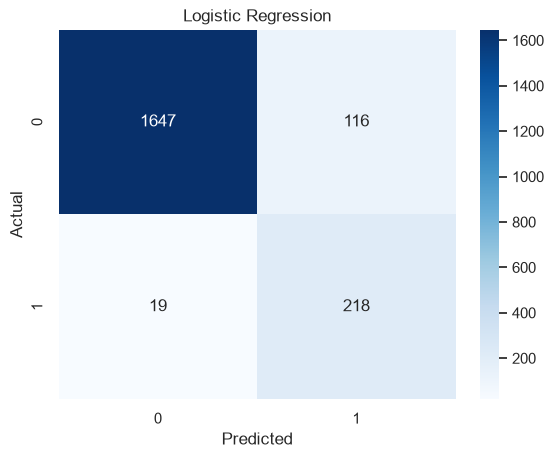

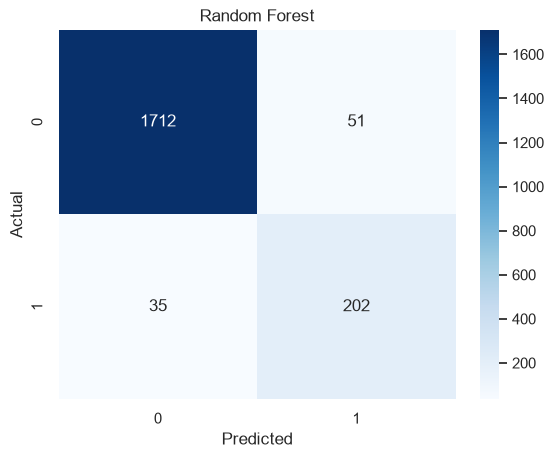

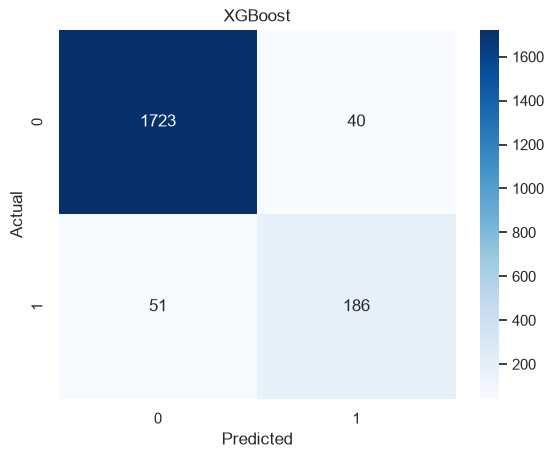

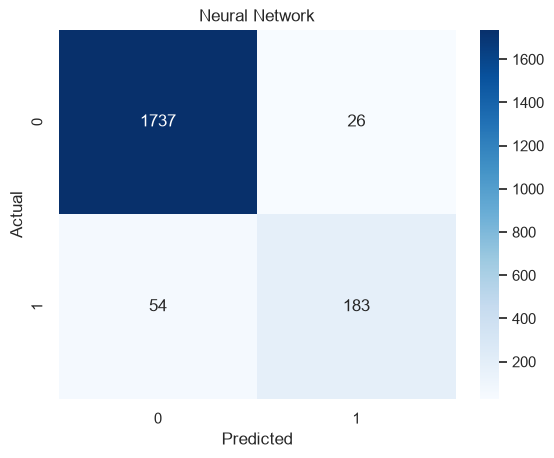

In [37]:
# Task 2: Confusion matrices
for name, (model, X_eval) in models.items():
    cm = confusion_matrix(y_test, model.predict(X_eval))
    sns.heatmap(data=cm, annot=True, fmt='d', cmap='Blues')
    plt.title(name)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

All four models reach a ROC-AUC of about 0.97. Logistic Regression has the highest recall but the lowest precision; the Neural Network is the other way round. In the confusion matrix, the bottom-left cell counts missed fraud cases, the top-right cell false alarms.

### 3.2 Feature Importance

`permutation_importance()` shuffles one feature at a time in the test data and measures how much the ROC-AUC drops. A large drop means the model relies on that feature.

1. Pick one model from `models` and compute its permutation importance.
2. Plot the ten most important features as a horizontal bar chart.
3. Do your new columns from 2.1 and 2.2 appear among them?

In [38]:
# Task 1: Permutation importance
name = 'Random Forest'
model, X_eval = models[name]
perm = permutation_importance(model, X_eval, y_test, n_repeats=10, scoring='roc_auc', random_state=42)

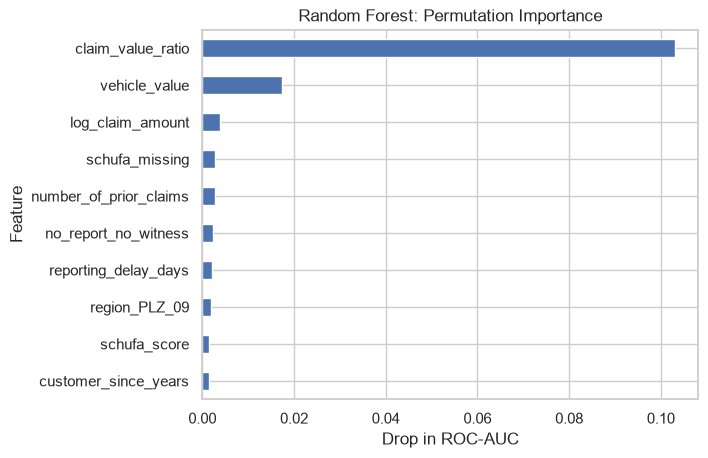

In [39]:
# Task 2: Top 10 features
importances = pd.Series(perm.importances_mean, index=X_test.columns)
top10 = importances.sort_values().tail(10)

top10.plot(kind='barh')
plt.title(f'{name}: Permutation Importance')
plt.xlabel('Drop in ROC-AUC')
plt.ylabel('Feature')
plt.show()

The engineered `claim_value_ratio` is by far the most important feature. `log_claim_amount`, `schufa_missing` and `no_report_no_witness` from 2.1 and 2.2 also appear among the top ten. `schufa_score` and `reporting_delay_days` correlate with fraud (1.3) but have only small importances: when features carry overlapping information, shuffling one of them hardly hurts the model.

### 3.3 Threshold Tuning

`predict()` flags a claim as fraud if its predicted probability is at least 0.5. A lower threshold catches more fraud (higher recall) but causes more false alarms (lower precision). The best threshold depends on the costs:

- Every flagged claim is investigated. An investigation costs 500 €.
- Every missed fraud case is paid out. It costs its `claim_amount`.

$$\text{Cost}(t) = 500 \cdot \text{number of flagged claims} + \text{sum of claim amounts of missed fraud cases}$$

1. For the model from 3.2, compute precision and recall for every threshold with `precision_recall_curve()` and plot recall against precision.
2. Compute the total cost for the thresholds 0.01, 0.02, ..., 0.99 and plot cost against threshold. Which threshold has the lowest cost? Compare it with 0.5.
3. Repeat Task 2 with investigation costs of 200 € and 3000 €. How does the best threshold move?

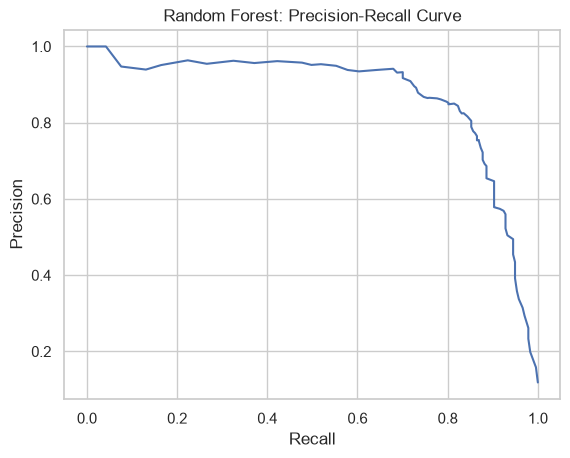

In [40]:
# Task 1: Precision-recall curve
y_proba = model.predict_proba(X_eval)[:, 1]
precisions, recalls, thresholds = precision_recall_curve(y_test, y_proba)
pr_curve = pd.Series(precisions, index=recalls)

pr_curve.plot(kind='line')
plt.title(f'{name}: Precision-Recall Curve')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.show()

In [41]:
# Task 2: Total cost per threshold
def cost_table(investigation_cost):
    rows = []
    for t in np.arange(1, 100) / 100:
        flagged = y_proba >= t
        missed = ~flagged & (y_test == 1)
        cost = investigation_cost * flagged.sum() + X_test.loc[missed, 'claim_amount'].sum()
        rows.append({'threshold': t, 'flagged': flagged.sum(),
                     'recall': recall_score(y_test, flagged), 'cost': cost})
    return pd.DataFrame(rows)

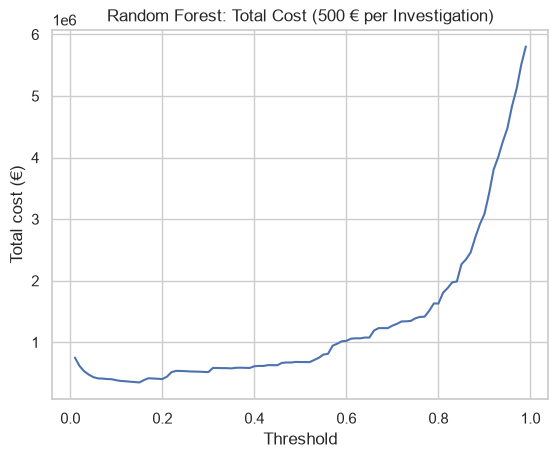

In [42]:
# Total cost with 500 € per investigation
costs = cost_table(500)
cost_curve = costs.set_index('threshold')['cost']

cost_curve.plot(kind='line')
plt.title(f'{name}: Total Cost (500 € per Investigation)')
plt.xlabel('Threshold')
plt.ylabel('Total cost (€)')
plt.show()

In [43]:
# Lowest cost
print(f"\n{sep}\nLowest Cost: costs.loc[costs['cost'].idxmin()]\n{sep}")
print(costs.loc[costs['cost'].idxmin()].round(3))


Lowest Cost: costs.loc[costs['cost'].idxmin()]
threshold         0.150
flagged         453.000
recall            0.945
cost         346248.890
Name: 14, dtype: float64


In [44]:
# Default threshold
print(f"\n{sep}\nDefault Threshold: costs[costs['threshold'] == 0.5]\n{sep}")
print(costs[costs['threshold'] == 0.5].round(3))


Default Threshold: costs[costs['threshold'] == 0.5]
    threshold  flagged  recall       cost
49        0.5      253   0.852  678187.71


In [45]:
# Task 3: Investigation costs of 200 € and 3000 €
best = {}
for investigation_cost in [200, 500, 3000]:
    costs = cost_table(investigation_cost)
    best[investigation_cost] = costs.loc[costs['cost'].idxmin()]

print(f"\n{sep}\nBest Threshold by Investigation Cost\n{sep}")
print(pd.DataFrame(best).T.round(3))


Best Threshold by Investigation Cost
      threshold  flagged  recall        cost
200        0.06    728.0   0.966   194515.81
500        0.15    453.0   0.945   346248.89
3000       0.45    268.0   0.865  1296648.76


With 500 € per investigation, the best threshold is 0.15: 453 of 2,000 claims are investigated and 94.5% of the fraud cases are caught. The total cost drops from 0.68 million € at the default threshold 0.5 to 0.35 million €. A missed fraud case costs far more than an investigation, so the best threshold lies well below 0.5. The more expensive an investigation, the higher the best threshold.

In practice, choose the threshold on a separate validation set, not on the test set.

## Summary

- **Exploration:** fraud rate, skewed distributions, fraud rates by group
- **Preparation and modelling:** duplicates, impossible values, indicator for missing values, feature engineering, one-hot encoding, stratified split, filling missing values, scaling, class weights
- **Evaluation:** precision, recall, F1-score, ROC-AUC, confusion matrix, permutation importance, cost-based threshold tuning

- [scikit-learn User Guide](https://scikit-learn.org/stable/user_guide.html)
- [XGBoost Documentation](https://xgboost.readthedocs.io/)